In [ ]:
# Dynamic Student Placement Prediction System

## Objective
##This project predicts student placement outcomes using Logistic Regression implemented:
##1. Using Scikit-learn
##2. From scratch using NumPy

##The system accepts a user-provided CSV dataset, preprocesses the data, trains the model, and evaluates prediction performance.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [ ]:

# While entering file path, DO NOT use quotes (" ")

file_path = input("Enter CSV file path: ")

df = pd.read_csv(file_path)

print("\nDataset Loaded Successfully!")
print("Selected File:", file_path)

display(df.head())

In [ ]:
print("Dataset Shape:\n")
print(df.shape)

print("\nDataset Information:\n")
df.info()

Dataset Shape:

(100, 4)

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Student_ID  100 non-null    int64  
 1   CGPA        100 non-null    float64
 2   IQ          100 non-null    int64  
 3   Placement   100 non-null    int64  
dtypes: float64(1), int64(3)
memory usage: 3.3 KB


In [ ]:
print("Missing Values:\n")

print(df.isnull().sum())

Missing Values:

Student_ID    0
CGPA          0
IQ            0
Placement     0
dtype: int64


In [ ]:
print("Statistical Summary:\n")

display(df.describe())

Statistical Summary:



,StudentID,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,SSC_Marks,HSC_Marks
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,7.698010,1.049200,2.026600,1.013200,79.449900,4.323960,69.159400,74.501500
std,2886.89568,0.640131,0.665901,0.867968,0.904272,8.159997,0.411622,10.430459,8.919527
min,1.00000,6.500000,0.000000,0.000000,0.000000,60.000000,3.000000,55.000000,57.000000
25%,2500.75000,7.400000,1.000000,1.000000,0.000000,73.000000,4.000000,59.000000,67.000000
50%,5000.50000,7.700000,1.000000,2.000000,1.000000,80.000000,4.400000,70.000000,73.000000
75%,7500.25000,8.200000,1.000000,3.000000,2.000000,87.000000,4.700000,78.000000,83.000000
max,10000.00000,9.100000,2.000000,3.000000,3.000000,90.000000,4.800000,90.000000,88.000000


In [ ]:
# Create a copy for encoding
df_encoded = df.copy()

# Initialize label encoder
le = LabelEncoder()

# Encode categorical columns
for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

print("Categorical Columns Encoded Successfully!")

Categorical Columns Encoded Successfully!


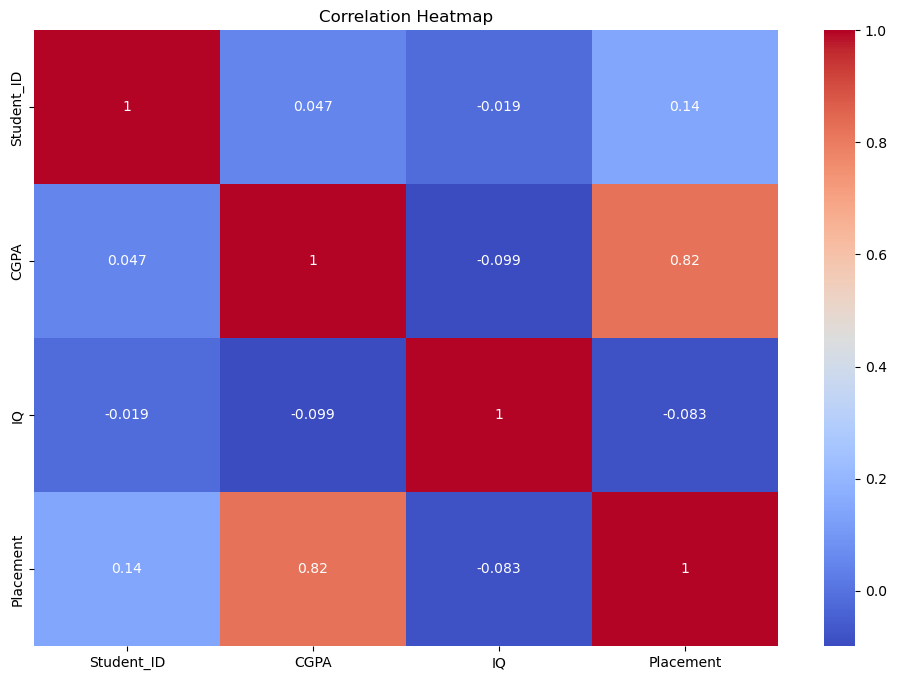

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
target_column = input("Enter target column name: ")

X = df_encoded.drop(target_column, axis=1)
y = df_encoded[target_column]

print("Target column selected:", target_column)

Enter target column name:  Placement


Target column selected: Placement


In [ ]:
# Fill all missing values with column mean
df_encoded = df_encoded.fillna(df_encoded.mean())

print("Missing Values Handled Successfully!")

print("\nRemaining Missing Values:\n")
print(df_encoded.isnull().sum())

Missing Values Handled Successfully!

Remaining Missing Values:

Student_ID    0
CGPA          0
IQ            0
Placement     0
dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train-test split completed!")

Train-test split completed!


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [ ]:
print("NaN values in X_train:")
print(np.isnan(X_train).sum())

print("\nNaN values in X_test:")
print(np.isnan(X_test).sum())

NaN values in X_train:
0

NaN values in X_test:
0


In [ ]:
model = LogisticRegression()

model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions Generated Successfully!")

Predictions Generated Successfully!


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 90.0 %


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:\n")
print(cm)

Confusion Matrix:

[[10  0]
 [ 2  8]]


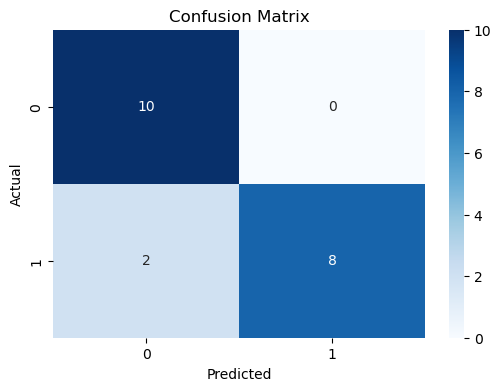

In [ ]:
plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      1.00      0.91        10
           1       1.00      0.80      0.89        10

    accuracy                           0.90        20
   macro avg       0.92      0.90      0.90        20
weighted avg       0.92      0.90      0.90        20



In [ ]:
# Logistic Regression From Scratch using NumPy

#In this section, Logistic Regression is implemented manually using NumPy without using Scikit-learn's built-in LogisticRegression model.

#The implementation includes:
#- Sigmoid Function
#- Cost Function
#- Gradient Descent
#- Weight Updates
#- Prediction Function

In [ ]:
# Convert scaled training data into NumPy arrays

X_train_np = np.array(X_train)
X_test_np = np.array(X_test)

y_train_np = np.array(y_train)
y_test_np = np.array(y_test)

print("Conversion to NumPy arrays completed!")

Conversion to NumPy arrays completed!


In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [ ]:
# Number of features
n_features = X_train_np.shape[1]

# Initialize weights and bias
weights = np.zeros(n_features)
bias = 0

print("Weights and bias initialized!")

Weights and bias initialized!


In [ ]:
def compute_cost(X, y, weights, bias):

    m = X.shape[0]

    # Linear model
    z = np.dot(X, weights) + bias

    # Apply sigmoid
    y_hat = sigmoid(z)

    # Avoid log(0)
    epsilon = 1e-15
    y_hat = np.clip(y_hat, epsilon, 1 - epsilon)

    # Compute cost
    cost = (-1 / m) * np.sum(
        y * np.log(y_hat) +
        (1 - y) * np.log(1 - y_hat)
    )

    return cost

In [ ]:
def gradient_descent(X, y, weights, bias, learning_rate, iterations):

    m = X.shape[0]

    cost_history = []

    for i in range(iterations):

        # Linear model
        z = np.dot(X, weights) + bias

        # Predictions
        y_hat = sigmoid(z)

        # Gradients
        dw = (1 / m) * np.dot(X.T, (y_hat - y))
        db = (1 / m) * np.sum(y_hat - y)

        # Update parameters
        weights = weights - learning_rate * dw
        bias = bias - learning_rate * db

        # Compute cost
        cost = compute_cost(X, y, weights, bias)

        cost_history.append(cost)

        # Print every 100 iterations
        if i % 100 == 0:
            print(f"Iteration {i}, Cost: {cost:.4f}")

    return weights, bias, cost_history

In [ ]:
learning_rate = 0.01
iterations = 1000

weights, bias, cost_history = gradient_descent(
    X_train_np,
    y_train_np,
    weights,
    bias,
    learning_rate,
    iterations
)

print("Training Completed!")

Iteration 0, Cost: 0.6914
Iteration 100, Cost: 0.5564
Iteration 200, Cost: 0.4711
Iteration 300, Cost: 0.4135
Iteration 400, Cost: 0.3722
Iteration 500, Cost: 0.3412
Iteration 600, Cost: 0.3169
Iteration 700, Cost: 0.2974
Iteration 800, Cost: 0.2814
Iteration 900, Cost: 0.2680
Training Completed!


In [ ]:
def predict(X, weights, bias):

    # Linear model
    z = np.dot(X, weights) + bias

    # Apply sigmoid
    probabilities = sigmoid(z)

    # Convert probabilities to class labels
    predictions = [1 if p >= 0.5 else 0 for p in probabilities]

    return np.array(predictions)

In [ ]:
y_pred_scratch = predict(X_test_np, weights, bias)

print("Predictions Generated Successfully!")

Predictions Generated Successfully!


In [ ]:
accuracy_scratch = accuracy_score(y_test_np, y_pred_scratch)

print("Accuracy (From Scratch Model):",
      round(accuracy_scratch * 100, 2), "%")

Accuracy (From Scratch Model): 90.0 %


In [ ]:
cm_scratch = confusion_matrix(y_test_np, y_pred_scratch)

print("Confusion Matrix:\n")
print(cm_scratch)

Confusion Matrix:

[[10  0]
 [ 2  8]]


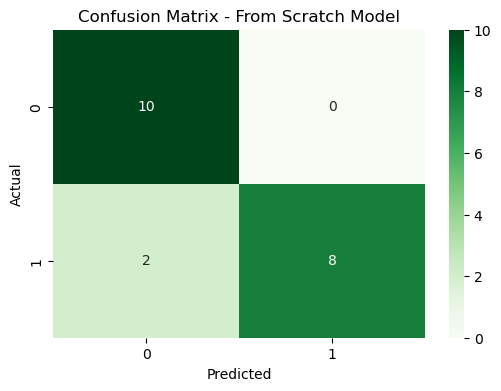

In [ ]:
plt.figure(figsize=(6,4))

sns.heatmap(
    cm_scratch,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Confusion Matrix - From Scratch Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
print(classification_report(y_test_np, y_pred_scratch))

              precision    recall  f1-score   support

           0       0.69      0.75      0.72        12
           1       0.90      0.87      0.89        31

    accuracy                           0.84        43
   macro avg       0.80      0.81      0.80        43
weighted avg       0.84      0.84      0.84        43



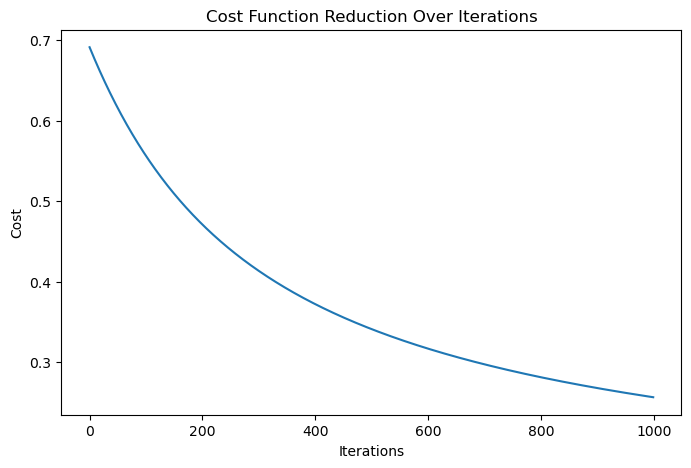

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(cost_history)

plt.title("Cost Function Reduction Over Iterations")
plt.xlabel("Iterations")
plt.ylabel("Cost")

plt.show()